# Cylinders modeled as multi-domain assemblies

This example computes the linear buckling load of a laminated cylinder under axial compression, modeled with five domains around the circumference, with and without blade stiffeners. It compares the two methods that connect the domains.

A `MultiDomain` assembly connects `Shell` domains, each with its own Ritz series, see `panels.multidomain.connections` and Castro and Donadon (2017). The function `create_cylinder` creates a cylinder with panels along its circumference, all in the group `'skin'`, and connects the last panel to the first one to close it. The connections impose the continuity of the displacements and rotations along the shared edges. With `conn_method='null-space'` they are imposed exactly, as linear constraints whose null space gives the independent unknowns, see [Exact connections with the null-space method](../multidomain_null_space.rst). With `conn_method='penalty'`, penalty stiffnesses approximate them, with the default constants of `calc_kt_kr`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from panels.multidomain import (cylinder_compression_lb_Nxx_cte,
        cylinder_compression_lb_Nxx_from_static,
        cylinder_blade_stiffened_compression_lb_Nxx_from_static)


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_group(md, c, group, ax, field='w', title=''):
    """Contour of ``field`` on the domains of ``group``, unrolled, with the
    circumferential coordinate along the horizontal axis"""
    panels = [p for p in md.panels if p.group == group]
    res = md.uvw(c, group, gridx=30, gridy=30)
    vmax = max(np.abs(f).max() for f in res[field])
    levels = np.linspace(-vmax, vmax, 31)
    for p, x, y, f in zip(panels, res['x'], res['y'], res[field]):
        cf = ax.contourf(y + p.y0, x + p.x0, f, levels=levels, cmap='coolwarm')
        ax.plot([p.y0, p.y0], [p.x0, p.x0 + p.a], 'k-', lw=0.5)
    ax.set_xlabel('circumferential coordinate $y$ (m)')
    ax.set_ylabel('axial coordinate $x$ (m)')
    ax.set_title(title)
    ax.set_aspect('equal')
    return cf

## Cylinder and constant pre-buckling stress

The cylinder has radius $r = 0.25$ m and length 0.5 m. The laminate is $[0/45/-45/90/-45/45]$ of carbon/epoxy plies of 0.125 mm, $(E_{11}, E_{22}, \nu_{12}, G_{12}, G_{13}, G_{23}) = (142.5, 8.7, 0.28, 5.1, 5.1, 5.1)$ GPa/-. There are five domains of $8 \times 12$ terms, with Sanders' kinematics, the default for cylinders. `cylinder_compression_lb_Nxx_cte` gives each panel a constant axial compression `Nxx` = -100 N/m and solves the linear buckling problem $(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0}$. The critical axial load is $\lambda N_{xx}$.

In [2]:
geometry = dict(height=0.5, r=0.25, plyt=0.125e-3,
                stack=[0, 45, -45, 90, -45, 45],
                laminaprop=(142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9),
                npanels=5, m=8, n=12, num_eigvalues=10)
Nxxs = [-100.]*5
results = {}
modes = {}
for method in ('penalty', 'null-space'):
    md, eigvals, eigvecs = cylinder_compression_lb_Nxx_cte(
        Nxxs=Nxxs, conn_method=method, **geometry)
    results[('constant Nxx', method)] = Nxxs[0]*eigvals[0]
    modes[('constant Nxx', method)] = (md, eigvecs[:, 0])
    print('%-10s: %d Ritz constants, critical Nxx = %.3f N/m'
          % (method, md.get_size(), Nxxs[0]*eigvals[0]))

penalty   : 1440 Ritz constants, critical Nxx = -47055.983 N/m


null-space: 1440 Ritz constants, critical Nxx = -47113.039 N/m


## Pre-buckling stress from a static analysis

`cylinder_compression_lb_Nxx_from_static` applies the same compression as a load distributed at the end $x = a$ of each panel. It solves the linear static problem and computes $\boldsymbol{K}_G$ from the Ritz constants of that solution. The stress field then follows the boundary conditions at the ends.

In [3]:
md, c, eigvals, eigvecs = cylinder_compression_lb_Nxx_from_static(
    Nxxs=Nxxs, conn_method='penalty', **geometry)
results[('Nxx from static', 'penalty')] = Nxxs[0]*eigvals[0]
modes[('Nxx from static', 'penalty')] = (md, eigvecs[:, 0])
print('critical Nxx = %.3f N/m' % (Nxxs[0]*eigvals[0]))

		Calculating kG for assembly...
		Calculating kG... 
		finished!
		Calculating kG... 
		finished!
		Calculating kG... 


		finished!
		Calculating kG... 
		finished!
		Calculating kG... 
		finished!
		finished!


critical Nxx = -47162.405 N/m


## Blade-stiffened cylinder

Blade stiffeners, one per panel, are added along the length of the cylinder as further domains connected to the skin, see `create_cylinder_blade_stiffened`. The blade domains are 20 mm wide, `width_blades`, with the laminate $[0/90/0]_4$. They carry the same axial compression as the skin, and the pre-buckling state comes from a static analysis.

In [4]:
for method in ('penalty', 'null-space'):
    md, c, eigvals, eigvecs = \
        cylinder_blade_stiffened_compression_lb_Nxx_from_static(
            stack_blades=[[0, 90, 0]*4]*5, width_blades=[0.02]*5,
            Nxxs_skin=Nxxs, Nxxs_blade=Nxxs, conn_method=method,
            **geometry)
    results[('blade-stiffened', method)] = Nxxs[0]*eigvals[0]
    modes[('blade-stiffened', method)] = (md, eigvecs[:, 0])
    print('%-10s: critical Nxx = %.3f N/m' % (method, Nxxs[0]*eigvals[0]))

penalty   : critical Nxx = -39993.838 N/m


null-space: critical Nxx = -41696.682 N/m


## Buckling modes

The first buckling modes of the skin, unrolled, with the domain boundaries as vertical lines:

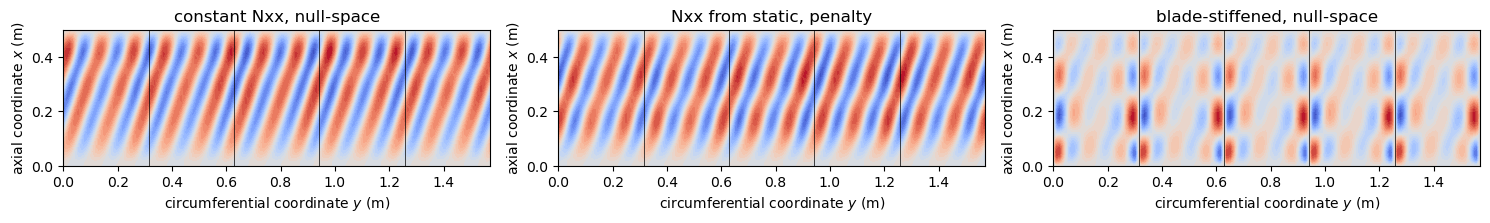

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, key in zip(axes, [('constant Nxx', 'null-space'),
                          ('Nxx from static', 'penalty'),
                          ('blade-stiffened', 'null-space')]):
    md, mode = modes[key]
    cf = plot_group(md, mode, 'skin', ax, title='%s, %s' % key)
fig.tight_layout()
plt.show()

## Results

The reference values are regression values of the panels unit tests `tests/multidomain/test_cylinder.py`, `test_cylinder_blade_stiffened.py` (penalty) and `test_null_space.py` (null-space), checked there within 0.1% (penalty) and $10^{-5}$ (null-space). No literature value is available for this laminate. With the default penalty constants, the connections leave some relative motion at the joints. For the stiffened cylinder this gives a critical load 4% lower than the null-space method, which imposes the connections exactly.

In [6]:
REF = {('constant Nxx', 'penalty'): (-47055.984, '`test_cylinder.py`'),
       ('constant Nxx', 'null-space'): (-47113.039, '`test_null_space.py`'),
       ('Nxx from static', 'penalty'): (-47162.406, '`test_cylinder.py`'),
       ('blade-stiffened', 'penalty'): (-39993.838,
                                        '`test_cylinder_blade_stiffened.py`'),
       ('blade-stiffened', 'null-space'): (-41696.682,
                                           '`test_null_space.py`')}
results_table([('%s, %s, critical $N_{xx}$ (N/m)' % key, results[key], ref,
                'regression value, %s' % src)
               for key, (ref, src) in REF.items()])

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| constant Nxx, penalty, critical $N_{xx}$ (N/m) | -47056 | -47056 | +1.49e-08 | regression value, `test_cylinder.py` |
| constant Nxx, null-space, critical $N_{xx}$ (N/m) | -47113 | -47113 | -9.74e-09 | regression value, `test_null_space.py` |
| Nxx from static, penalty, critical $N_{xx}$ (N/m) | -47162.4 | -47162.4 | +1.68e-08 | regression value, `test_cylinder.py` |
| blade-stiffened, penalty, critical $N_{xx}$ (N/m) | -39993.8 | -39993.8 | -4.15e-09 | regression value, `test_cylinder_blade_stiffened.py` |
| blade-stiffened, null-space, critical $N_{xx}$ (N/m) | -41696.7 | -41696.7 | +7.12e-09 | regression value, `test_null_space.py` |

## References

1. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.